# 04 · Feature Engineering + LightGBM + Optuna (v2 — RAM optimizada)

## Cambios respecto a v1
- FE solo sobre variables seleccionadas (no todas las 150 columnas)
- Checkpoints en parquet para no rehacer trabajo si se corta el runtime
- Las features se construyen en bloques y se liberan variables intermedias
- El modelo trabaja sobre el parquet de FE ya construido

## Flujo con checkpoints
```
[CHECKPOINT A] dataset_target_construido.parquet   ← ya existe (notebook 03)
      ↓
  Interpolación + FE
      ↓
[CHECKPOINT B] dataset_fe.parquet                  ← se genera acá
      ↓
  LightGBM + Optuna
      ↓
[CHECKPOINT C] mejores_params_optuna.json          ← se genera acá
      ↓
  Walk-forward + Submission
      ↓
[CHECKPOINT D] submission_YYYYMMDD_HHMM.csv        ← output final
```
Si el runtime se corta, retomás desde el checkpoint más reciente.

---
**Proyecto:** Predicción de Churn Bancario · Data Mining en EyF  
**Etapa:** 4 — Modelado (v2)  
**Última actualización:** 2026-10

## 0 · Setup

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!pip install optuna lightgbm --quiet

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 8.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 21.5 MB/s eta 0:00:00


In [3]:
import gc
import warnings
import json
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import lightgbm as lgb
import optuna
from sklearn.metrics import roc_auc_score

warnings.filterwarnings('ignore')
optuna.logging.set_verbosity(optuna.logging.WARNING)
plt.rcParams['figure.dpi'] = 110

# ─── Rutas ────────────────────────────────────────────────────────────────────
RUTA_BASE  = Path('/content/drive/MyDrive/Maestría Data Mining/DM en EyF')
RUTA_COMP  = RUTA_BASE / 'Competencia 1'
RUTA_COMP.mkdir(parents=True, exist_ok=True)

# Checkpoints
CKPT_A = RUTA_COMP / 'dataset_target_construido.parquet'   # input (ya existe)
CKPT_B = RUTA_COMP / 'dataset_fe.parquet'                  # post FE
CKPT_C = RUTA_COMP / 'mejores_params_optuna.json'          # params

ARCHIVO_SUBMISSION = RUTA_COMP / f'submission_{datetime.now().strftime("%Y%m%d_%H%M")}.csv'
ARCHIVO_METRICAS   = RUTA_COMP / 'metricas_experimentos.csv'

# ─── Constantes ───────────────────────────────────────────────────────────────
COL_ID      = 'numero_de_cliente'
COL_PERIODO = 'foto_mes'
TARGET_RAW  = 'clase_ternaria'
TARGET      = 'es_baja2'

MESES_CON_TARGET = [202103, 202104, 202105, 202106]
MES_PREDECIR     = 202108

GANANCIA_TP =  1_072_500
COSTO_FP    =    -27_500
SEED        = 42

def mem_mb(df):
    return df.memory_usage(deep=True).sum() / 1024**2

print('Checkpoints:')
for ck in [CKPT_A, CKPT_B, CKPT_C]:
    print(f'  {ck.name}: {"✓ existe" if ck.exists() else "✗ pendiente"}')

Checkpoints:
  dataset_target_construido.parquet: ✓ existe
  dataset_fe.parquet: ✗ pendiente
  mejores_params_optuna.json: ✗ pendiente


## 1 · Funciones de ganancia

In [4]:
def calcular_ganancia(y_true, y_pred_bin):
    tp = ((y_true == 1) & (y_pred_bin == 1)).sum()
    fp = ((y_true == 0) & (y_pred_bin == 1)).sum()
    return tp * GANANCIA_TP + fp * COSTO_FP

def ganancia_por_threshold(y_true, y_prob, n=500):
    thresholds = np.linspace(0.001, 0.999, n)
    rows = []
    for t in thresholds:
        pred = (y_prob >= t).astype(int)
        tp = ((y_true == 1) & (pred == 1)).sum()
        fp = ((y_true == 0) & (pred == 1)).sum()
        rows.append({'threshold': t,
                     'ganancia': tp * GANANCIA_TP + fp * COSTO_FP,
                     'tp': int(tp), 'fp': int(fp),
                     'n_intervenidos': int(tp + fp)})
    return pd.DataFrame(rows)

def threshold_optimo(y_true, y_prob):
    df_t = ganancia_por_threshold(y_true, y_prob)
    return df_t.loc[df_t['ganancia'].idxmax()].to_dict()

def plot_ganancia_threshold(y_true, y_prob, titulo=''):
    df_t = ganancia_por_threshold(y_true, y_prob)
    opt  = df_t.loc[df_t['ganancia'].idxmax()].to_dict()

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    ax = axes[0]
    ax.plot(df_t['threshold'], df_t['ganancia'] / 1e9, color='#4C72B0', lw=2)
    ax.axvline(opt['threshold'], color='#C44E52', ls='--', lw=1.5,
               label=f"Óptimo: {opt['threshold']:.4f}")
    ax.axhline(0, color='gray', ls=':', lw=1)
    ax.set_title(f'Ganancia vs Threshold {titulo}', fontweight='bold')
    ax.set_xlabel('Threshold')
    ax.set_ylabel('Ganancia ($B)')
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:.2f}B'))
    ax.legend(fontsize=9)

    ax = axes[1]
    ax.plot(df_t['threshold'], df_t['n_intervenidos'], color='#DD8452', lw=2)
    ax.axvline(opt['threshold'], color='#C44E52', ls='--', lw=1.5)
    ax.set_title(f'Clientes a intervenir vs Threshold {titulo}', fontweight='bold')
    ax.set_xlabel('Threshold')
    ax.set_ylabel('N clientes')
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))

    plt.tight_layout()
    plt.show()

    print(f"  Threshold óptimo:   {opt['threshold']:.5f}")
    print(f"  Ganancia:           ${opt['ganancia']:>15,.0f}")
    print(f"  TP detectados:      {opt['tp']:,}")
    print(f"  FP (en vano):       {opt['fp']:,}")
    print(f"  Total intervenidos: {opt['n_intervenidos']:,}")
    return opt

print('✓ Funciones de ganancia listas.')

✓ Funciones de ganancia listas.


## 2 · Feature Engineering

### Lógica de checkpoint
Si `dataset_fe.parquet` ya existe en Drive, lo cargamos directamente y saltamos el FE.  
Si no existe, lo construimos y lo guardamos.

**Esto significa que si el runtime se corta después de guardar el CKPT_B, alcanza con correr desde la sección 3 en adelante.**

In [5]:
if CKPT_B.exists():
    print(f'✓ Checkpoint B encontrado — cargando dataset_fe.parquet...')
    df = pd.read_parquet(CKPT_B)
    print(f'  {df.shape[0]:,} filas × {df.shape[1]} columnas — {mem_mb(df):.1f} MB')
    FEATURE_COLS = [c for c in df.columns
                    if c not in {COL_ID, COL_PERIODO, TARGET_RAW, TARGET}]
    print(f'  Features disponibles: {len(FEATURE_COLS)}')
    print('  → Saltá a la sección 3 (Preparación de splits).')
else:
    print('✗ Checkpoint B no encontrado — ejecutar celdas de FE a continuación.')

✗ Checkpoint B no encontrado — ejecutar celdas de FE a continuación.


In [6]:
# ── Solo correr si CKPT_B NO existe ──────────────────────────────────────────
# Si la celda anterior imprimió '✓ Checkpoint B encontrado', saltá esta celda

if not CKPT_B.exists():
    print('Cargando CKPT_A (dataset con target)...')
    df = pd.read_parquet(CKPT_A)
    df = df.sort_values([COL_ID, COL_PERIODO]).reset_index(drop=True)
    print(f'  {df.shape[0]:,} filas × {df.shape[1]} columnas — {mem_mb(df):.1f} MB')

Cargando CKPT_A (dataset con target)...
  983,061 filas × 156 columnas — 411.6 MB


In [7]:
# ── Solo correr si CKPT_B NO existe ──────────────────────────────────────────
if not CKPT_B.exists():

    # ── Interpolación ────────────────────────────────────────────────────────
    # Solo floats que NO sean variables de tarjeta (su NaN es estructural)
    NO_INTERPOLAR = {
        COL_ID, COL_PERIODO, TARGET_RAW, TARGET,
        'active_quarter', 'cliente_vip', 'internet',
        'tcallcenter', 'thomebanking', 'tmobile_app',
        'Master_status', 'Visa_status', 'Master_delinquency', 'Visa_delinquency',
    }
    NO_INTERPOLAR.update([c for c in df.columns
                          if c.startswith('c')
                          and df[c].dtype in ['uint8','uint16','uint32','int8','int16','int32']])
    # Excluimos también los bloques Visa_ y Master_ — su NaN = sin tarjeta
    NO_INTERPOLAR.update([c for c in df.columns
                          if c.startswith('Visa_') or c.startswith('Master_')])

    COLS_INTERPOLAR = [c for c in df.select_dtypes(include=['float32','float64']).columns
                       if c not in NO_INTERPOLAR]

    nulos_antes = df[COLS_INTERPOLAR].isna().sum().sum()
    df[COLS_INTERPOLAR] = (
        df.groupby(COL_ID)[COLS_INTERPOLAR]
        .transform(lambda s: s.interpolate(method='linear', limit=1, limit_direction='both'))
    )
    nulos_despues = df[COLS_INTERPOLAR].isna().sum().sum()
    print(f'Interpolación: {nulos_antes - nulos_despues:,} NaN rellenados')
    print(f'  RAM: {mem_mb(df):.1f} MB')
    gc.collect()

Interpolación: 44,094 NaN rellenados
  RAM: 411.6 MB


In [8]:
# ── Solo correr si CKPT_B NO existe ──────────────────────────────────────────
if not CKPT_B.exists():

    # ── Variables seleccionadas para FE ──────────────────────────────────────
    # NO generamos lags para las 150 cols — solo las más predictivas.
    # Criterio: variables de volumen/comportamiento con alta correlación histórica
    # con churn en datos bancarios (basado en EDA + literatura).
    # Las variables de tarjeta (Visa/Master) van directo al modelo sin lags
    # porque ya tienen muchos NaN — lag de un NaN sigue siendo NaN.

    COLS_FE = [
        # Rentabilidad y márgenes
        'mrentabilidad', 'mrentabilidad_annual', 'mcomisiones',
        'mactivos_margen', 'mpasivos_margen',
        # Cuentas y saldos
        'mcuentas_saldo', 'mcuenta_corriente', 'mcaja_ahorro',
        'mcaja_ahorro_dolares',
        # Transacciones digitales
        'chomebanking_transacciones', 'cmobile_app_trx', 'ctrx_quarter',
        # Productos
        'cproductos', 'tcuentas',
        # Tarjetas (conteos de transacciones — menos NaN que montos)
        'ctarjeta_visa_transacciones', 'ctarjeta_master_transacciones',
        # Payroll
        'mpayroll',
        # Transferencias
        'ctransferencias_emitidas', 'ctransferencias_recibidas',
        # ATM
        'catm_trx', 'matm',
        # Préstamos
        'mprestamos_personales', 'mprestamos_hipotecarios',
        # Perfil
        'cliente_antiguedad',
    ]
    # Filtramos solo las que existen
    COLS_FE = [c for c in COLS_FE if c in df.columns]
    print(f'Variables base para FE: {len(COLS_FE)}')

    # ── Lag(t-1) y Delta ─────────────────────────────────────────────────────
    # Generamos de a una para controlar RAM
    print('Generando lags y deltas...')
    for col in COLS_FE:
        lag = df.groupby(COL_ID)[col].shift(1).astype('float32')
        df[f'{col}_lag1']   = lag
        df[f'{col}_delta1'] = (df[col] - lag).astype('float32')
        # Delta relativo — clippeado para no tener inf
        df[f'{col}_drel1']  = (df[f'{col}_delta1'] / lag.abs().replace(0, np.nan)).clip(-10, 10).astype('float32')
        del lag

    gc.collect()
    print(f'  Columnas totales: {df.shape[1]} — RAM: {mem_mb(df):.1f} MB')

Variables base para FE: 24
Generando lags y deltas...
  Columnas totales: 228 — RAM: 681.6 MB


In [9]:
# ── Solo correr si CKPT_B NO existe ──────────────────────────────────────────
if not CKPT_B.exists():

    # ── Tendencia 3 meses (solo variables clave) ──────────────────────────────
    COLS_TEND = ['mrentabilidad', 'mcuentas_saldo', 'mcuenta_corriente',
                 'mcaja_ahorro', 'mcomisiones', 'cproductos',
                 'chomebanking_transacciones', 'ctrx_quarter']
    COLS_TEND = [c for c in COLS_TEND if c in df.columns]

    print(f'Generando tendencias para {len(COLS_TEND)} variables...')

    def slope_3(w):
        if np.isnan(w).any(): return np.nan
        return float(np.polyfit([0, 1, 2], w, 1)[0])

    for col in COLS_TEND:
        df[f'{col}_tend3'] = (
            df.groupby(COL_ID)[col]
            .transform(lambda s: s.rolling(3, min_periods=3).apply(slope_3, raw=True))
            .astype('float32')
        )

    gc.collect()
    print(f'  Columnas totales: {df.shape[1]} — RAM: {mem_mb(df):.1f} MB')

Generando tendencias para 8 variables...
  Columnas totales: 236 — RAM: 711.6 MB


In [10]:
# ── Solo correr si CKPT_B NO existe ──────────────────────────────────────────
if not CKPT_B.exists():

    # ── Ratios ────────────────────────────────────────────────────────────────
    def safe_ratio(a, b, clip=100):
        return (a / b.replace(0, np.nan)).clip(-clip, clip).astype('float32')

    df['r_ahorro_saldo']   = safe_ratio(df['mcaja_ahorro'], df['mcuentas_saldo'].abs())
    df['r_comis_rentab']   = safe_ratio(df['mcomisiones'], df['mrentabilidad'].abs())
    df['r_digitalizacion'] = (
        (df.get('chomebanking_transacciones', pd.Series(0, index=df.index)).fillna(0) +
         df.get('cmobile_app_trx', pd.Series(0, index=df.index)).fillna(0)) /
        df.get('ctrx_quarter', pd.Series(1, index=df.index)).replace(0, np.nan)
    ).clip(0, 1).astype('float32')

    if 'mtarjeta_visa_consumo' in df.columns and 'Visa_mlimitecompra' in df.columns:
        df['r_visa_utilizacion'] = safe_ratio(
            df['mtarjeta_visa_consumo'], df['Visa_mlimitecompra'])

    if 'mtarjeta_master_consumo' in df.columns and 'Master_mlimitecompra' in df.columns:
        df['r_master_utilizacion'] = safe_ratio(
            df['mtarjeta_master_consumo'], df['Master_mlimitecompra'])

    # ── Flags ─────────────────────────────────────────────────────────────────
    df['flag_primer_mes'] = (
        df.groupby(COL_ID)[COL_PERIODO].transform('min') == df[COL_PERIODO]
    ).astype('int8')

    if 'Visa_msaldototal' in df.columns:
        df['flag_tiene_visa']   = df['Visa_msaldototal'].notna().astype('int8')
    if 'Master_msaldototal' in df.columns:
        df['flag_tiene_master'] = df['Master_msaldototal'].notna().astype('int8')

    df['flag_tiene_prestamo'] = (
        (df.get('cprestamos_personales',   pd.Series(0, index=df.index)).fillna(0) +
         df.get('cprestamos_hipotecarios', pd.Series(0, index=df.index)).fillna(0) +
         df.get('cprestamos_prendarios',   pd.Series(0, index=df.index)).fillna(0)) > 0
    ).astype('int8')

    gc.collect()
    print(f'FE completo — {df.shape[1]} columnas — RAM: {mem_mb(df):.1f} MB')

FE completo — 245 columnas — RAM: 734.1 MB


In [11]:
# ── Solo correr si CKPT_B NO existe ──────────────────────────────────────────
# Guardamos CKPT_B y liberamos RAM
if not CKPT_B.exists():
    print(f'Guardando CKPT_B ({mem_mb(df):.1f} MB en RAM)...')
    df.to_parquet(CKPT_B, index=False, engine='pyarrow')
    tam = CKPT_B.stat().st_size / 1024**2
    print(f'✓ Guardado: {CKPT_B.name} ({tam:.1f} MB en disco)')

    # Definimos FEATURE_COLS
    FEATURE_COLS = [c for c in df.columns
                    if c not in {COL_ID, COL_PERIODO, TARGET_RAW, TARGET}]
    print(f'  Features para el modelo: {len(FEATURE_COLS)}')
else:
    print('CKPT_B ya existía — nada que guardar.')

Guardando CKPT_B (734.1 MB en RAM)...
✓ Guardado: dataset_fe.parquet (281.8 MB en disco)
  Features para el modelo: 241


## 3 · Preparación de splits para walk-forward

**Desde acá se puede retomar si el runtime se cortó después de guardar CKPT_B.**  
Correr desde la celda de Setup (sección 0) hasta acá — el df viene del parquet.

In [12]:
# Si venimos de un runtime nuevo, df se cargó en la sección 2 (checkpoint B)
# Si no, ya está en memoria
assert 'df' in dir(), 'df no está en memoria — corré desde la sección 2'

EXCLUIR = {COL_ID, COL_PERIODO, TARGET_RAW, TARGET}
FEATURE_COLS = [c for c in df.columns if c not in EXCLUIR]

# Ratio de imbalance para scale_pos_weight
mask_entren = df[COL_PERIODO].isin(MESES_CON_TARGET) & df[TARGET].notna()
y_tot = df.loc[mask_entren, TARGET]
SCALE_POS_WEIGHT = float((y_tot == 0).sum() / (y_tot == 1).sum())
del y_tot; gc.collect()

FOLDS = [
    {'nombre': 'fold_2', 'train': [202103],               'test': 202104},
    {'nombre': 'fold_3', 'train': [202103, 202104],       'test': 202105},
    {'nombre': 'fold_4', 'train': [202103, 202104, 202105], 'test': 202106},
]

def get_split(meses_train, mes_test):
    mt = df[COL_PERIODO].isin(meses_train) & df[TARGET].notna()
    me = (df[COL_PERIODO] == mes_test)     & df[TARGET].notna()
    return (df.loc[mt, FEATURE_COLS], df.loc[mt, TARGET].astype(int),
            df.loc[me, FEATURE_COLS], df.loc[me, TARGET].astype(int))

print(f'scale_pos_weight: {SCALE_POS_WEIGHT:.1f}')
print(f'Features: {len(FEATURE_COLS)}')
print(f'RAM: {mem_mb(df):.1f} MB')
print()
for fold in FOLDS:
    Xtr, ytr, Xte, yte = get_split(fold['train'], fold['test'])
    print(f"{fold['nombre']}: train={len(ytr):,} (baja2={ytr.sum()}) | test={len(yte):,} (baja2={yte.sum()})")

scale_pos_weight: 158.8
Features: 241
RAM: 734.1 MB

fold_2: train=161,881 (baja2=960) | test=162,320 (baja2=1139)
fold_3: train=324,201 (baja2=2099) | test=162,625 (baja2=870)
fold_4: train=486,826 (baja2=2969) | test=163,240 (baja2=1098)


## 4 · Baseline LightGBM

In [13]:
PARAMS_BASE = {
    'objective': 'binary', 'metric': 'binary_logloss',
    'boosting_type': 'gbdt', 'verbosity': -1, 'n_jobs': -1,
    'random_state': SEED,
    'num_leaves': 31, 'learning_rate': 0.05, 'n_estimators': 500,
    'min_child_samples': 50,   # más alto que v1 — evita overfitting en positivos
    'subsample': 0.8, 'subsample_freq': 1, 'colsample_bytree': 0.8,
    'scale_pos_weight': SCALE_POS_WEIGHT,
}

print('Entrenando baseline (fold_4)...')
Xtr, ytr, Xte, yte = get_split([202103, 202104, 202105], 202106)

modelo_base = lgb.LGBMClassifier(**PARAMS_BASE)
modelo_base.fit(
    Xtr, ytr,
    eval_set=[(Xte, yte)],
    callbacks=[lgb.early_stopping(50, verbose=False), lgb.log_evaluation(-1)]
)

prob_base = modelo_base.predict_proba(Xte)[:, 1]
auc_base  = roc_auc_score(yte, prob_base)
print(f'AUC baseline: {auc_base:.4f}')

del Xtr, ytr; gc.collect()

Entrenando baseline (fold_4)...
AUC baseline: 0.8685


162

=== BASELINE — fold_4 ===


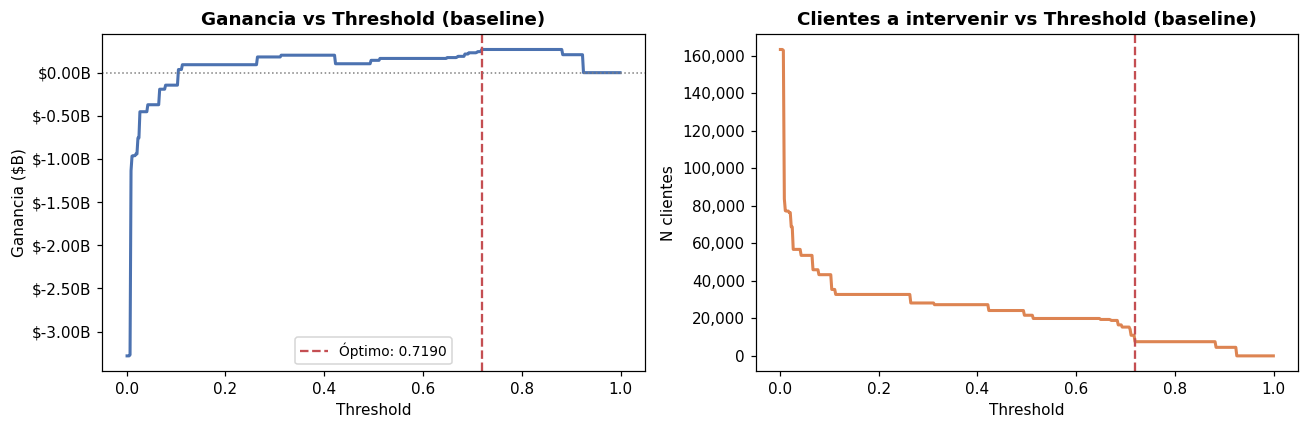

  Threshold óptimo:   0.71900
  Ganancia:           $    268,565,000
  TP detectados:      433.0
  FP (en vano):       7,121.0
  Total intervenidos: 7,554.0


6655

In [14]:
print('=== BASELINE — fold_4 ===')
opt_base = plot_ganancia_threshold(yte.values, prob_base, '(baseline)')
del Xte, yte; gc.collect()

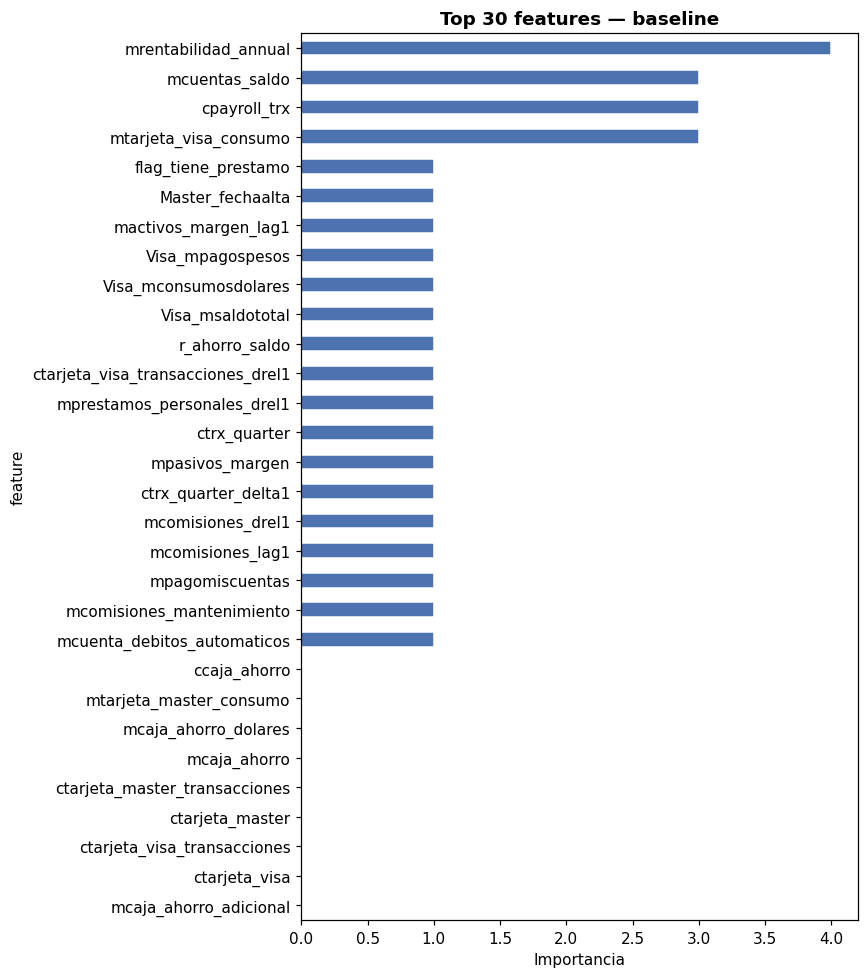

Top 15:
                    feature  importance
       mrentabilidad_annual           4
      mtarjeta_visa_consumo           3
             mcuentas_saldo           3
               cpayroll_trx           3
            mpasivos_margen           1
  mcomisiones_mantenimiento           1
            mpagomiscuentas           1
mcuenta_debitos_automaticos           1
               ctrx_quarter           1
        ctrx_quarter_delta1           1
          mcomisiones_drel1           1
           mcomisiones_lag1           1
       mactivos_margen_lag1           1
           Visa_mpagospesos           1
      Visa_mconsumosdolares           1

Features con importancia=0: 220 (candidatas a eliminar en próxima iteración)


In [15]:
# Feature importance
fi = pd.DataFrame({'feature': modelo_base.feature_name_,
                   'importance': modelo_base.feature_importances_
                   }).sort_values('importance', ascending=False)

fig, ax = plt.subplots(figsize=(8, 9))
fi.head(30).sort_values('importance').plot(
    kind='barh', x='feature', y='importance', ax=ax,
    color='#4C72B0', edgecolor='white', legend=False)
ax.set_title('Top 30 features — baseline', fontweight='bold')
ax.set_xlabel('Importancia')
plt.tight_layout()
plt.show()

print('Top 15:')
print(fi.head(15).to_string(index=False))

# Features con importancia 0 — candidatas a eliminar
cero_imp = fi[fi['importance'] == 0]
print(f'\nFeatures con importancia=0: {len(cero_imp)} (candidatas a eliminar en próxima iteración)')

## 5 · Optimización con Optuna

### Lógica de checkpoint
Si `mejores_params_optuna.json` existe, lo cargamos y saltamos la optimización.  
Útil si Optuna ya corrió en una sesión anterior.

In [16]:
if CKPT_C.exists():
    print(f'✓ Checkpoint C encontrado — cargando params...')
    with open(CKPT_C) as f:
        params_guardados = json.load(f)
    PARAMS_OPT = {k: v for k, v in params_guardados.items()
                  if k not in {'ganancia_optuna_fold4', 'n_trials', 'fecha'}}
    PARAMS_OPT.update({'objective': 'binary', 'metric': 'binary_logloss',
                       'boosting_type': 'gbdt', 'verbosity': -1,
                       'n_jobs': -1, 'random_state': SEED})
    print(f'  Ganancia Optuna (fold4): ${params_guardados["ganancia_optuna_fold4"]:,.0f}')
    print('  → Saltá a la sección 6 (Walk-forward).')
else:
    print('✗ Checkpoint C no encontrado — ejecutar Optuna a continuación.')

✗ Checkpoint C no encontrado — ejecutar Optuna a continuación.


In [18]:
# ── Solo correr si CKPT_C NO existe ──────────────────────────────────────────
if not CKPT_C.exists():

    Xtr_opt, ytr_opt, Xte_opt, yte_opt = get_split([202103, 202104, 202105], 202106)
    yte_opt_arr = yte_opt.values

    def objective_optuna(trial):
        max_depth  = trial.suggest_int('max_depth', 3, 12)
        num_leaves = trial.suggest_int('num_leaves', 2, min(256, 2**max_depth - 1))

        params = {
            'objective': 'binary', 'metric': 'binary_logloss',
            'boosting_type': 'gbdt', 'verbosity': -1,
            'n_jobs': -1, 'random_state': SEED,
            'num_leaves':        num_leaves,
            'max_depth':         max_depth,
            'learning_rate':     trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
            'n_estimators':      trial.suggest_int('n_estimators', 100, 800, step=50),
            'min_child_samples': trial.suggest_int('min_child_samples', 20, 300),
            'feature_fraction':  trial.suggest_float('feature_fraction', 0.4, 1.0),
            'bagging_fraction':  trial.suggest_float('bagging_fraction', 0.4, 1.0),
            'bagging_freq':      trial.suggest_int('bagging_freq', 1, 7),
            'reg_alpha':         trial.suggest_float('reg_alpha', 1e-8, 10.0, log=True),
            'reg_lambda':        trial.suggest_float('reg_lambda', 1e-8, 10.0, log=True),
            'scale_pos_weight':  trial.suggest_float('scale_pos_weight',
                                                      SCALE_POS_WEIGHT / 4,
                                                      SCALE_POS_WEIGHT * 1.5),
        }
        model = lgb.LGBMClassifier(**params)
        model.fit(Xtr_opt, ytr_opt,
                  eval_set=[(Xte_opt, yte_opt)],
                  callbacks=[lgb.early_stopping(30, verbose=False), lgb.log_evaluation(-1)])
        prob = model.predict_proba(Xte_opt)[:, 1]
        del model; gc.collect()
        return threshold_optimo(yte_opt_arr, prob)['ganancia']

    # ── N_TRIALS: 30 para exploración rápida, 100+ para producción ───────────
    N_TRIALS = 30

    study = optuna.create_study(
        direction='maximize',
        sampler=optuna.samplers.TPESampler(seed=SEED),
        study_name='lgbm_churn_ganancia'
    )
    study.optimize(objective_optuna, n_trials=N_TRIALS, show_progress_bar=True)

    del Xtr_opt, ytr_opt, Xte_opt; gc.collect()

    print(f'\n✓ Optuna completado — {N_TRIALS} trials')
    print(f'Mejor ganancia: ${study.best_value:,.0f}')
    print('Mejores parámetros:')
    for k, v in study.best_params.items():
        print(f'  {k}: {v}')

    # Guardamos CKPT_C
    PARAMS_OPT = {
        'objective': 'binary', 'metric': 'binary_logloss',
        'boosting_type': 'gbdt', 'verbosity': -1,
        'n_jobs': -1, 'random_state': SEED,
        **study.best_params
    }
    guardar = {**study.best_params,
               'ganancia_optuna_fold4': study.best_value,
               'n_trials': N_TRIALS,
               'fecha': datetime.now().isoformat()}
    with open(CKPT_C, 'w') as f:
        json.dump(guardar, f, indent=2)
    print(f'✓ Checkpoint C guardado: {CKPT_C.name}')

  0%|          | 0/30 [00:00<?, ?it/s]


✓ Optuna completado — 30 trials
Mejor ganancia: $420,420,000
Mejores parámetros:
  max_depth: 3
  num_leaves: 3
  learning_rate: 0.06826077177826517
  n_estimators: 150
  min_child_samples: 177
  feature_fraction: 0.9100618386331337
  bagging_fraction: 0.7068367523579071
  bagging_freq: 4
  reg_alpha: 0.8652498156497086
  reg_lambda: 3.0672910733236344e-05
  scale_pos_weight: 84.20477731412916
✓ Checkpoint C guardado: mejores_params_optuna.json


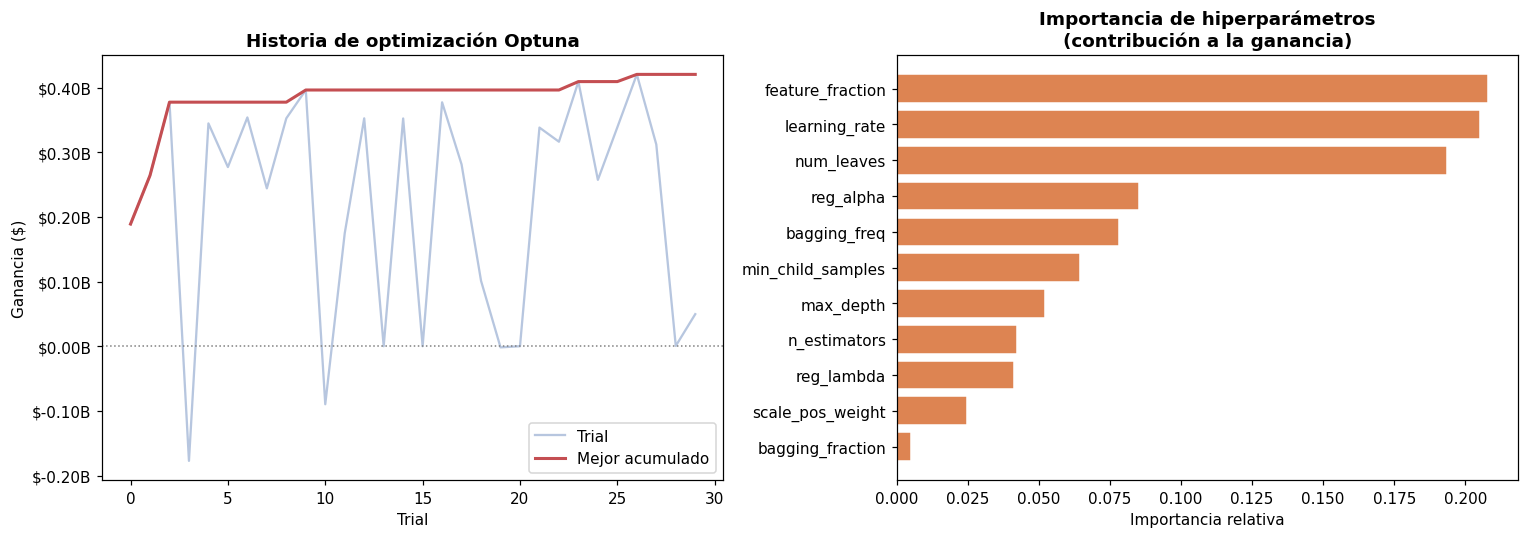

In [19]:
# ── Gráficos Optuna (solo si se ejecutó en esta sesión) ───────────────────────
if not CKPT_C.exists() or 'study' not in dir():
    print('(Gráficos de Optuna solo disponibles si se corrió en esta sesión)')
else:
    valores   = [t.value for t in study.trials if t.value is not None]
    mejor_acc = pd.Series(valores).cummax()

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    ax = axes[0]
    ax.plot(valores, alpha=0.4, color='#4C72B0', label='Trial')
    ax.plot(mejor_acc, color='#C44E52', lw=2, label='Mejor acumulado')
    ax.axhline(0, color='gray', ls=':', lw=1)
    ax.set_title('Historia de optimización Optuna', fontweight='bold')
    ax.set_xlabel('Trial')
    ax.set_ylabel('Ganancia ($)')
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x/1e9:.2f}B'))
    ax.legend()

    ax = axes[1]
    try:
        importances = optuna.importance.get_param_importances(study)
        params_i = list(importances.keys())
        vals_i   = list(importances.values())
        sidx     = np.argsort(vals_i)
        ax.barh([params_i[i] for i in sidx], [vals_i[i] for i in sidx],
                color='#DD8452', edgecolor='white')
        ax.set_title('Importancia de hiperparámetros\n(contribución a la ganancia)', fontweight='bold')
        ax.set_xlabel('Importancia relativa')
    except Exception:
        ax.text(0.5, 0.5, 'Requiere más trials', ha='center', va='center', transform=ax.transAxes)

    plt.tight_layout()
    plt.show()

## 6 · Walk-forward completo con parámetros optimizados


  FOLD_2 — test: 202104
AUC: 0.9044


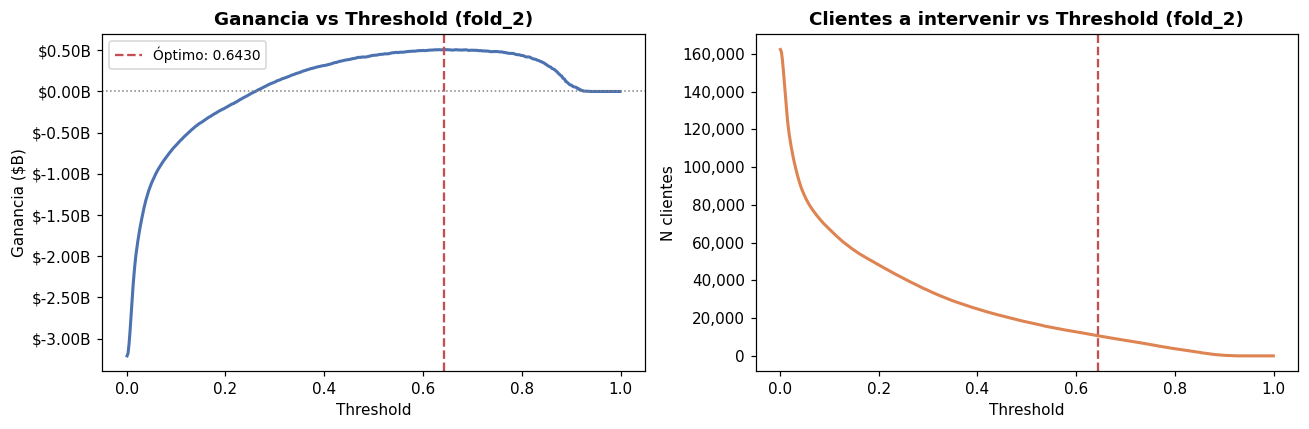

  Threshold óptimo:   0.64300
  Ganancia:           $    509,795,000
  TP detectados:      731.0
  FP (en vano):       9,971.0
  Total intervenidos: 10,702.0

  FOLD_3 — test: 202105
AUC: 0.8882


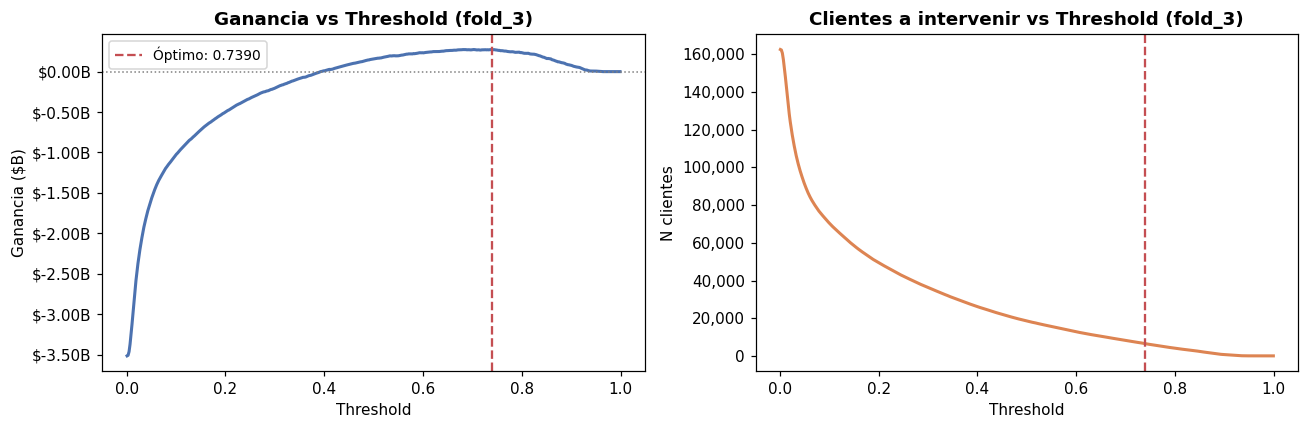

  Threshold óptimo:   0.73900
  Ganancia:           $    273,762,500
  TP detectados:      412.0
  FP (en vano):       6,113.0
  Total intervenidos: 6,525.0

  FOLD_4 — test: 202106
AUC: 0.8991


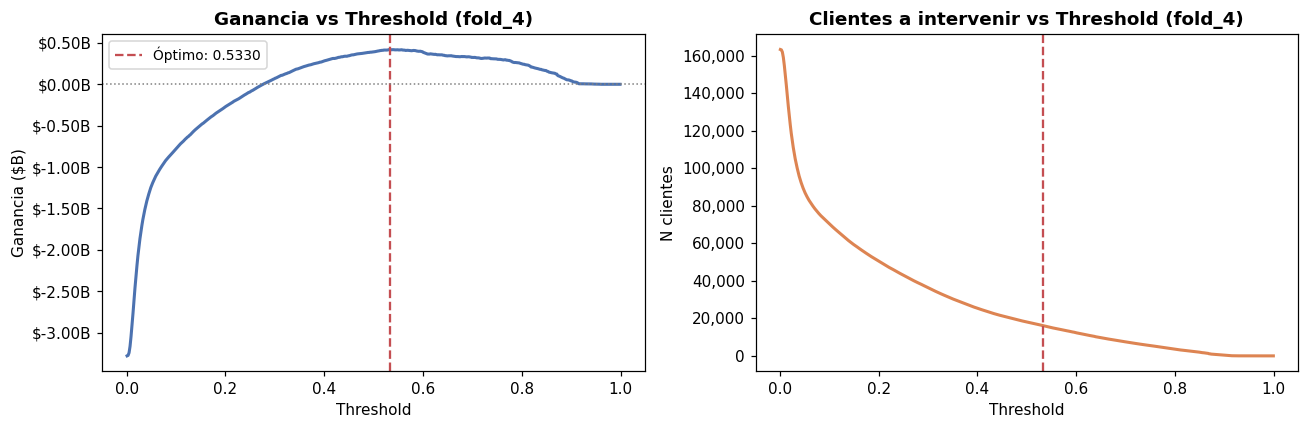

  Threshold óptimo:   0.53300
  Ganancia:           $    420,420,000
  TP detectados:      785.0
  FP (en vano):       15,327.0
  Total intervenidos: 16,112.0

RESUMEN WALK-FORWARD
  fold  mes_test    auc    ganancia  threshold_opt    tp      fp
fold_2    202104 0.9044 509795000.0          0.643 731.0  9971.0
fold_3    202105 0.8882 273762500.0          0.739 412.0  6113.0
fold_4    202106 0.8991 420420000.0          0.533 785.0 15327.0


In [20]:
resultados_wf = []

for fold in FOLDS:
    print(f"\n{'='*55}")
    print(f"  {fold['nombre'].upper()} — test: {fold['test']}")
    print('='*55)

    Xtr, ytr, Xte, yte = get_split(fold['train'], fold['test'])

    modelo = lgb.LGBMClassifier(**PARAMS_OPT)
    modelo.fit(
        Xtr, ytr,
        eval_set=[(Xte, yte)],
        callbacks=[lgb.early_stopping(50, verbose=False), lgb.log_evaluation(-1)]
    )

    prob = modelo.predict_proba(Xte)[:, 1]
    auc  = roc_auc_score(yte, prob)
    print(f'AUC: {auc:.4f}')

    opt = plot_ganancia_threshold(yte.values, prob, f"({fold['nombre']})")

    resultados_wf.append({
        'fold': fold['nombre'], 'mes_test': fold['test'],
        'n_train': len(ytr), 'n_test': len(yte),
        'n_baja2_test': int(yte.sum()),
        'auc': round(auc, 4),
        'ganancia': opt['ganancia'],
        'threshold_opt': opt['threshold'],
        'tp': opt['tp'], 'fp': opt['fp'],
        'n_intervenidos': opt['n_intervenidos'],
    })

    del Xtr, ytr, Xte, yte, modelo, prob; gc.collect()

resultados_df = pd.DataFrame(resultados_wf)
print(f"\n{'='*55}\nRESUMEN WALK-FORWARD\n{'='*55}")
print(resultados_df[['fold','mes_test','auc','ganancia','threshold_opt','tp','fp']].to_string(index=False))

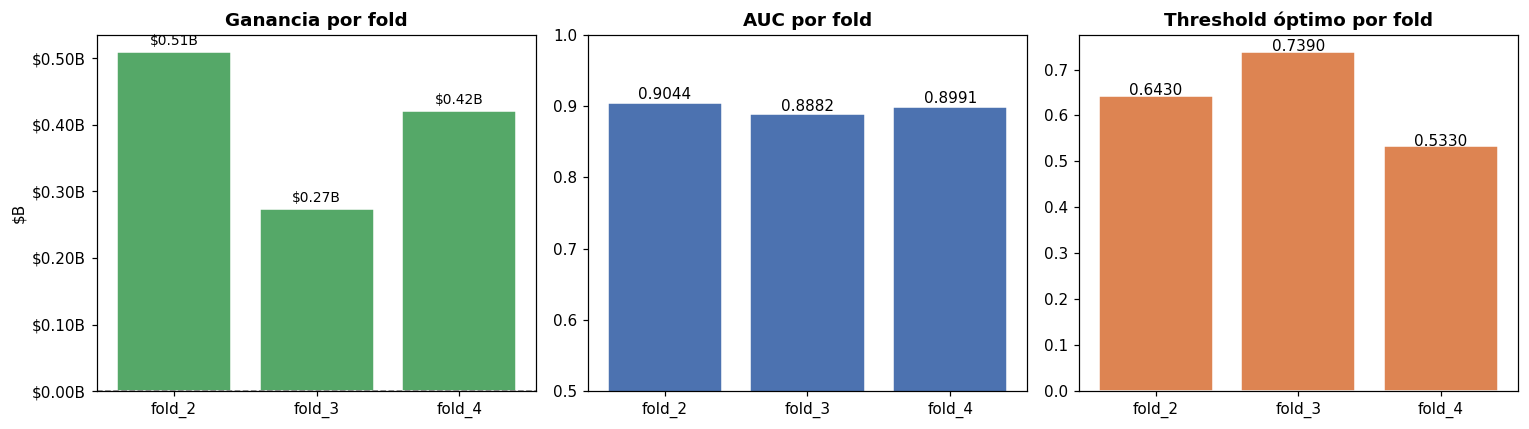

✓ Métricas guardadas: metricas_experimentos.csv


In [21]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
labels = resultados_df['fold'].tolist()

ax = axes[0]
cols = ['#55A868' if g > 0 else '#C44E52' for g in resultados_df['ganancia']]
bars = ax.bar(labels, resultados_df['ganancia'] / 1e9, color=cols, edgecolor='white')
ax.set_title('Ganancia por fold', fontweight='bold')
ax.set_ylabel('$B')
ax.axhline(0, color='gray', ls='--', lw=1)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:.2f}B'))
for bar, v in zip(bars, resultados_df['ganancia']):
    ax.text(bar.get_x() + bar.get_width()/2,
            bar.get_height() + 0.01 * (1 if v >= 0 else -1),
            f'${v/1e9:.2f}B', ha='center', fontsize=9)

ax = axes[1]
ax.bar(labels, resultados_df['auc'], color='#4C72B0', edgecolor='white')
ax.set_title('AUC por fold', fontweight='bold')
ax.set_ylim(0.5, 1.0)
for i, v in enumerate(resultados_df['auc']):
    ax.text(i, v + 0.005, f'{v:.4f}', ha='center', fontsize=10)

ax = axes[2]
ax.bar(labels, resultados_df['threshold_opt'], color='#DD8452', edgecolor='white')
ax.set_title('Threshold óptimo por fold', fontweight='bold')
for i, v in enumerate(resultados_df['threshold_opt']):
    ax.text(i, v + 0.001, f'{v:.4f}', ha='center', fontsize=10)

plt.tight_layout()
plt.show()

# Guardar métricas
resultados_df['timestamp'] = datetime.now().isoformat()
if ARCHIVO_METRICAS.exists():
    hist = pd.read_csv(ARCHIVO_METRICAS)
    resultados_df = pd.concat([hist, resultados_df], ignore_index=True)
resultados_df.to_csv(ARCHIVO_METRICAS, index=False)
print(f'✓ Métricas guardadas: {ARCHIVO_METRICAS.name}')

## 7 · Análisis de errores (fold_4)

In [22]:
Xtr_f4, ytr_f4, Xte_f4, yte_f4 = get_split([202103, 202104, 202105], 202106)

modelo_f4 = lgb.LGBMClassifier(**PARAMS_OPT)
modelo_f4.fit(Xtr_f4, ytr_f4,
              eval_set=[(Xte_f4, yte_f4)],
              callbacks=[lgb.early_stopping(50, verbose=False), lgb.log_evaluation(-1)])

prob_f4 = modelo_f4.predict_proba(Xte_f4)[:, 1]
opt_f4  = threshold_optimo(yte_f4.values, prob_f4)
pred_f4 = (prob_f4 >= opt_f4['threshold']).astype(int)

# Construimos df de análisis sobre el mes de test
idx_test = df[(df[COL_PERIODO] == 202106) & df[TARGET].notna()].index
df_err = df.loc[idx_test, [COL_ID, 'cliente_edad', 'cliente_antiguedad',
                             'mrentabilidad', 'cproductos', 'mcuentas_saldo',
                             'chomebanking_transacciones', 'mcomisiones']].copy()
df_err['prob'] = prob_f4
df_err['pred'] = pred_f4
df_err['real'] = yte_f4.values
df_err['tipo'] = 'TN'
df_err.loc[(df_err.real==1) & (df_err.pred==1), 'tipo'] = 'TP'
df_err.loc[(df_err.real==0) & (df_err.pred==1), 'tipo'] = 'FP'
df_err.loc[(df_err.real==1) & (df_err.pred==0), 'tipo'] = 'FN'

print('Matriz de confusión (fold_4):')
print(df_err['tipo'].value_counts())
print(f"Ganancia: ${opt_f4['ganancia']:,.0f}")

del Xtr_f4, ytr_f4; gc.collect()

Matriz de confusión (fold_4):
tipo
TN    146815
FP     15327
TP       785
FN       313
Name: count, dtype: int64
Ganancia: $420,420,000


7904

Perfil TP vs FN (churners detectados vs perdidos):
                    TP_media   FN_media   dif_%
cliente_edad           46.91      47.53     1.3
cliente_antiguedad    105.95     125.13    18.1
mrentabilidad        2006.36    2193.41     9.3
cproductos              6.06       7.27    19.9
mcuentas_saldo      -6967.22  108921.14  1663.3
mcomisiones          1331.53    1749.54    31.4
prob                    0.74       0.31   -58.9


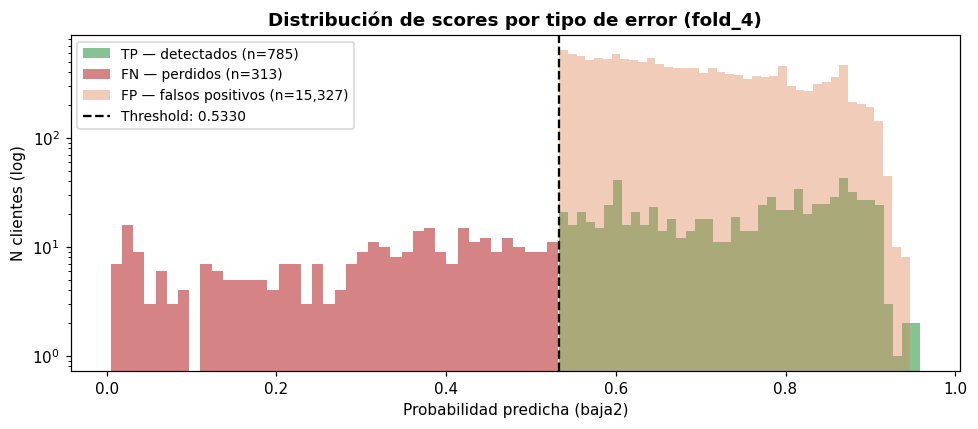

2805

In [23]:
# Perfil TP vs FN
vars_perfil = ['cliente_edad', 'cliente_antiguedad', 'mrentabilidad',
               'cproductos', 'mcuentas_saldo', 'mcomisiones', 'prob']
vars_perfil = [v for v in vars_perfil if v in df_err.columns]

churners = df_err[df_err['real'] == 1]
perfil = pd.concat([
    churners[churners['tipo']=='TP'][vars_perfil].mean().rename('TP_media'),
    churners[churners['tipo']=='FN'][vars_perfil].mean().rename('FN_media'),
], axis=1)
perfil['dif_%'] = ((perfil['FN_media'] - perfil['TP_media']) / perfil['TP_media'].abs() * 100).round(1)
print('Perfil TP vs FN (churners detectados vs perdidos):')
print(perfil.round(2))

# Gráfico de scores
fig, ax = plt.subplots(figsize=(9, 4))
for tipo, color, alpha, label in [
    ('TP', '#55A868', 0.7, 'TP — detectados'),
    ('FN', '#C44E52', 0.7, 'FN — perdidos'),
    ('FP', '#DD8452', 0.4, 'FP — falsos positivos'),
]:
    sub = df_err[df_err['tipo'] == tipo]['prob']
    if len(sub): ax.hist(sub, bins=40, alpha=alpha, color=color, label=f'{label} (n={len(sub):,})')
ax.axvline(opt_f4['threshold'], color='black', ls='--', lw=1.5,
           label=f"Threshold: {opt_f4['threshold']:.4f}")
ax.set_yscale('log')
ax.set_title('Distribución de scores por tipo de error (fold_4)', fontweight='bold')
ax.set_xlabel('Probabilidad predicha (baja2)')
ax.set_ylabel('N clientes (log)')
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

del df_err, churners, Xte_f4, yte_f4; gc.collect()

## 8 · Predicción final sobre 202108

In [24]:
# Threshold: promedio de los 3 folds (más robusto que usar solo uno)
threshold_final = float(np.mean(resultados_df['threshold_opt'].values[-3:]))
print(f'Thresholds por fold: {resultados_df["threshold_opt"].values[-3:]}')
print(f'Threshold final (promedio): {threshold_final:.5f}')

# Train final: todos los meses con target real
mask_tf = df[COL_PERIODO].isin(MESES_CON_TARGET) & df[TARGET].notna()
X_tf = df.loc[mask_tf, FEATURE_COLS]
y_tf = df.loc[mask_tf, TARGET].astype(int)

# Datos a predecir
mask_pred = df[COL_PERIODO] == MES_PREDECIR
X_pred = df.loc[mask_pred, FEATURE_COLS]
ids_pred = df.loc[mask_pred, COL_ID]

print(f'\nTrain final: {len(y_tf):,} filas (baja2={y_tf.sum():,})')
print(f'Clientes a predecir (202108): {len(X_pred):,}')

modelo_final = lgb.LGBMClassifier(**PARAMS_OPT)
modelo_final.fit(X_tf, y_tf, callbacks=[lgb.log_evaluation(-1)])

prob_final = modelo_final.predict_proba(X_pred)[:, 1]
pred_final = (prob_final >= threshold_final).astype(int)

del X_tf, y_tf; gc.collect()

print(f'\nClientes a intervenir: {pred_final.sum():,} ({pred_final.mean()*100:.2f}%)')

Thresholds por fold: [0.643 0.739 0.533]
Threshold final (promedio): 0.63833

Train final: 650,066 filas (baja2=4,067)
Clientes a predecir (202108): 164,647

Clientes a intervenir: 11,652 (7.08%)


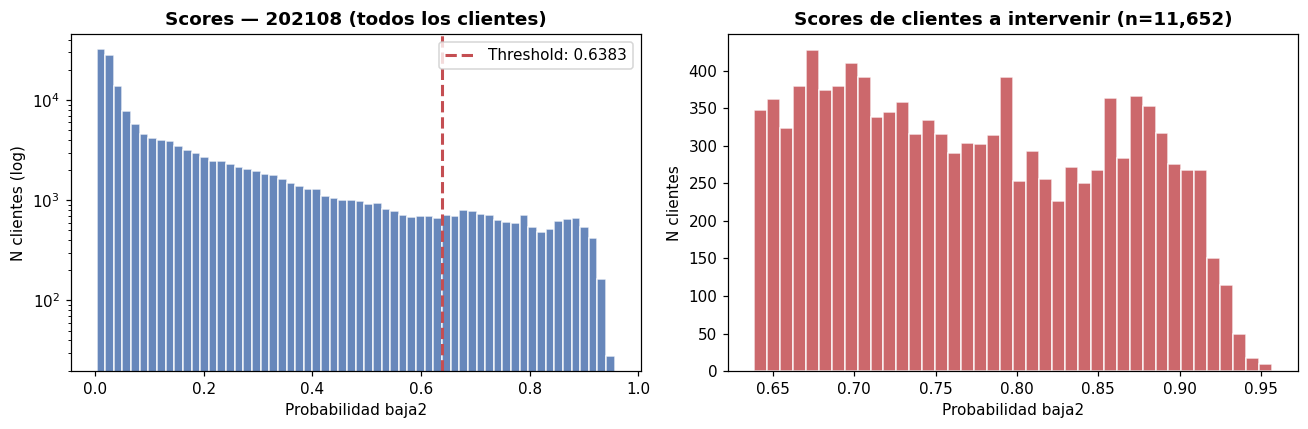

In [25]:
# Distribución de scores finales
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

ax = axes[0]
ax.hist(prob_final, bins=60, color='#4C72B0', edgecolor='white', alpha=0.85)
ax.axvline(threshold_final, color='#C44E52', ls='--', lw=2,
           label=f'Threshold: {threshold_final:.4f}')
ax.set_yscale('log')
ax.set_title('Scores — 202108 (todos los clientes)', fontweight='bold')
ax.set_xlabel('Probabilidad baja2')
ax.set_ylabel('N clientes (log)')
ax.legend()

ax = axes[1]
pred1 = prob_final[pred_final == 1]
ax.hist(pred1, bins=40, color='#C44E52', edgecolor='white', alpha=0.85)
ax.set_title(f'Scores de clientes a intervenir (n={len(pred1):,})', fontweight='bold')
ax.set_xlabel('Probabilidad baja2')
ax.set_ylabel('N clientes')

plt.tight_layout()
plt.show()

In [ ]:
# Submission
submission = pd.DataFrame({
    COL_ID:       ids_pred.values,
    'Predicted':  pred_final,
    'prob_baja2': prob_final.round(6),
})
submission.to_csv(ARCHIVO_SUBMISSION, index=False)
print(f'✓ Submission: {ARCHIVO_SUBMISSION.name}')
print(f'  Pred=1: {submission["Predicted"].sum():,} | Pred=0: {(submission["Predicted"]==0).sum():,}')
print(submission.head())

In [ ]:
print('=' * 65)
print('RESUMEN FINAL')
print('=' * 65)
print(f'CKPT_B: {CKPT_B.name} ({CKPT_B.stat().st_size/1024**2:.1f} MB)')
print(f'CKPT_C: {CKPT_C.name}')
print(f'Submission: {ARCHIVO_SUBMISSION.name}')
print(f'Métricas: {ARCHIVO_METRICAS.name}')
print()
print('Walk-forward:')
for _, row in resultados_df.drop_duplicates('fold').iterrows():
    g = row.get('ganancia', 0)
    print(f"  {row['fold']}: ${g:>15,.0f} | AUC={row.get('auc',0):.4f} | thresh={row.get('threshold_opt',0):.4f}")
print()
print(f'Threshold final: {threshold_final:.5f}')
print(f'Clientes a intervenir: {pred_final.sum():,}')

del df; gc.collect()
print('\n✓ Notebook completada.')